# Module 8 - Two-Layer Neural Network
### Part 1 - Handwritten Digits

This notebook demonstrates the `TwoLayerNetKeras` class using MNIST. The network uses the pixel values from one handwritten digit as its input.

* Input layer - 784 pixel values
* Hidden layer - 100 neurons with ReLU activation
* Output layer - 10 neurons with softmax activation, one for each digit

### MNIST Input

Each image has 28 rows and 28 columns. The following cell puts the 784 pixel values into one row and divides each value by 255 to give an input between 0 and 1.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
epochs = 10
batch_size = 64

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train = X_train.reshape(len(X_train), -1).astype("float32") / 255.0
X_test = X_test.reshape(len(X_test), -1).astype("float32") / 255.0
print(f"Training pool: {len(X_train):,} images")
print(f"Held-out test set: {len(X_test):,} images")


Training pool: 60,000 images
Held-out test set: 10,000 images


### TwoLayerNetKeras

The class creates the hidden layer and output layer using Keras. It uses RMSprop to update the weights during training.

In [2]:
class TwoLayerNetKeras(keras.Sequential):
    """A dense hidden layer followed by a dense digit classifier."""

    def __init__(self, input_size=784, hidden_size=100, output_size=10):
        super().__init__(
            [
                keras.Input(shape=(input_size,)),
                layers.Dense(hidden_size, activation="relu"),
                layers.Dense(output_size, activation="softmax"),
            ],
            name="two_layer_net",
        )
        self.compile(
            optimizer="rmsprop",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )


model = TwoLayerNetKeras()
model.summary()



Model: "two_layer_net"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 100)               78500     
                                                                 
 dense_1 (Dense)             (None, 10)                1010      
                                                                 
Total params: 79510 (310.59 KB)
Trainable params: 79510 (310.59 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### Train the Network

The network trains for 10 epochs. It uses 48,000 images to update the weights and the remaining 12,000 training images to check validation accuracy. The plots show the loss and accuracy after each epoch.

In [3]:
history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    verbose=2,
)

Epoch 1/10


750/750 - 1s - loss: 0.3303 - accuracy: 0.9091 - val_loss: 0.1832 - val_accuracy: 0.9487 - 1s/epoch - 1ms/step
Epoch 2/10
750/750 - 1s - loss: 0.1582 - accuracy: 0.9545 - val_loss: 0.1381 - val_accuracy: 0.9619 - 724ms/epoch - 965us/step
Epoch 3/10
750/750 - 1s - loss: 0.1142 - accuracy: 0.9675 - val_loss: 0.1116 - val_accuracy: 0.9671 - 729ms/epoch - 972us/step
Epoch 4/10
750/750 - 1s - loss: 0.0896 - accuracy: 0.9740 - val_loss: 0.1047 - val_accuracy: 0.9686 - 784ms/epoch - 1ms/step
Epoch 5/10
750/750 - 1s - loss: 0.0729 - accuracy: 0.9793 - val_loss: 0.0959 - val_accuracy: 0.9739 - 763ms/epoch - 1ms/step
Epoch 6/10
750/750 - 1s - loss: 0.0615 - accuracy: 0.9825 - val_loss: 0.0927 - val_accuracy: 0.9736 - 722ms/epoch - 963us/step
Epoch 7/10
750/750 - 1s - loss: 0.0525 - accuracy: 0.9851 - val_loss: 0.0902 - val_accuracy: 0.9736 - 732ms/epoch - 976us/step
Epoch 8/10
750/750 - 1s - loss: 0.0458 - accuracy: 0.9865 - val_loss: 0.0865 - val_accuracy: 0.9749 - 735ms/epoch - 98

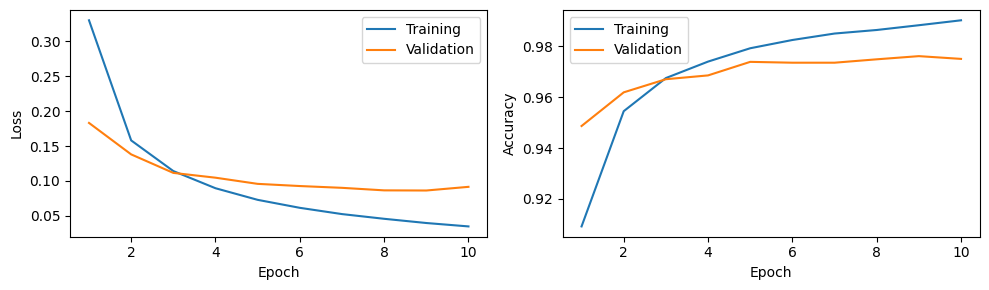

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ("loss", "accuracy")):
    ax.plot(range(1, epochs + 1), history.history[metric], label="Training")
    ax.plot(range(1, epochs + 1), history.history[f"val_{metric}"], label="Validation")
    ax.set(xlabel="Epoch", ylabel=metric.capitalize())
    ax.legend()
fig.tight_layout()
plt.show()

### Test the Network

The highest output value gives the predicted digit. Comparing these predictions with the MNIST labels gives 9,741 correct out of 10,000, or 97.41% accuracy.

In [5]:
test = model.evaluate(X_test, y_test, batch_size=batch_size, verbose=0, return_dict=True)
test_probabilities = model.predict(X_test, batch_size=batch_size, verbose=0)
test_predictions = test_probabilities.argmax(axis=1)
prediction_accuracy = np.mean(test_predictions == y_test)
np.testing.assert_allclose(prediction_accuracy, test["accuracy"], atol=1e-6)

print(f"Test loss: {test['loss']:.4f}")
print(f"Test accuracy: {test['accuracy']:.2%}")
print(f"Correct predictions: {np.count_nonzero(test_predictions == y_test):,}/{len(y_test):,}")

Test loss: 0.0792
Test accuracy: 97.74%
Correct predictions: 9,774/10,000


### Sample Output

Shows the first 10 test images with the actual digit and the output from the network.

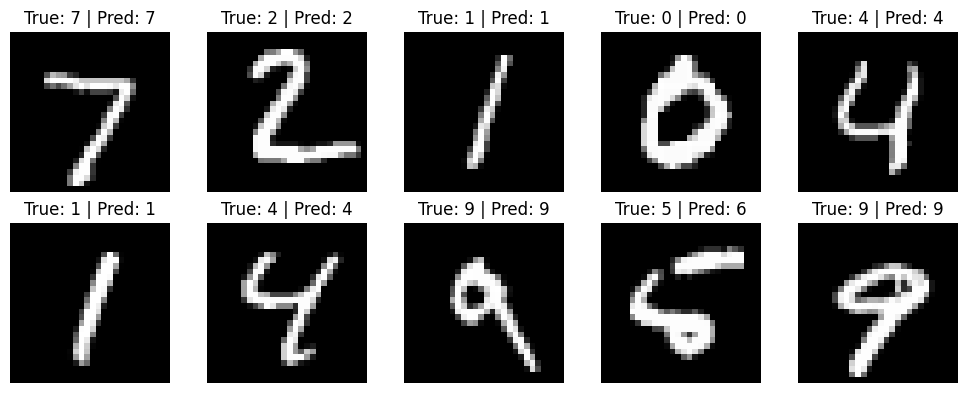

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for sample, ax in enumerate(axes.flat):
    ax.imshow(X_test[sample].reshape(28, 28), cmap="gray")
    ax.set_title(f"True: {y_test[sample]} | Pred: {test_predictions[sample]}")
    ax.axis("off")
fig.tight_layout()
plt.show()